# Lab 03: Character-Level Tiny Transformer from Scratch (`TinyStories`)

**Module:** PUSL 3205 — Large Language Models and Generative AI
**Lab 03:** Tiny Transformer Implementation
**Author:** Kumarage Isiwara Didulani

---

## Overview
This notebook builds, trains, and evaluates a compact autoregressive **Tiny Transformer** (`80,715` parameters) from scratch using PyTorch on the `roneneldan/TinyStories` dataset. The pipeline covers character-level tokenization, causal self-attention masking, cross-entropy training across 15 epochs, perplexity evaluation, autoregressive story generation and model checkpointing.

### Step 1: Load the TinyStories Dataset

**Question:**
> *How do we import and explore the `roneneldan/TinyStories` dataset from Hugging Face for character-level language modeling[cite: 38]?*

**Explanation:**
* **Dataset Source**: `TinyStories` contains synthetic short stories generated by LLMs, making it ideal for training compact, fast Transformer models from scratch[cite: 38].
* **Environment Setup**: We check for available GPU acceleration (`cuda`) using PyTorch and load a manageable subset (`train[:1000]`) to keep training times efficient[cite: 38, 39].

In [1]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
from datasets import load_dataset

# Set random seed for reproducibility
torch.manual_seed(42)

# Check for GPU
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Execution Device:", device)

# Load a subset of TinyStories from Hugging Face
dataset = load_dataset(
    "roneneldan/TinyStories",
    split="train[:1000]"
)

# Split into train (90%) and validation (10%) sets
dataset = dataset.train_test_split(
    test_size=0.1,
    seed=42
)

train_text = "\n".join(dataset["train"]["text"])
val_text = "\n".join(dataset["test"]["text"])

print("Training stories count:", len(dataset["train"]))
print("Validation stories count:", len(dataset["test"]))
print("\nSample training text preview:\n", train_text[:300])

C:\Users\ISIWARA KUMARAGE\Documents\NLP_Year_3\nlp_rag\rag_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Execution Device: cpu


Training stories count: 900
Validation stories count: 100

Sample training text preview:
 Anna and Ben are friends. They like to play together. Today, they have a task. They have to find a beautiful flower for their teacher.

They walk in the park. They see many flowers. Some are red, some are yellow, some are pink. But they want to find the most beautiful flower of all.

They see a big 


### Step 2: Preprocess the Text

**Question:**
> *How do we convert raw text strings into numerical token IDs using character-level tokenization[cite: 38, 39]?*

**Explanation:**
* **Character Vocabulary**: We extract all unique characters across our training and validation corpora to form our vocabulary dictionary.
* **Encoding & Decoding**: `stoi` maps characters to integers, and `itos` maps integer IDs back to characters so we can inspect generated text later[cite: 39].

In [2]:
# Build character vocabulary
chars = sorted(set(train_text + val_text))
vocab_size = len(chars)

stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for i, ch in enumerate(chars)}

def encode(text):
    return [stoi[ch] for ch in text if ch in stoi]

def decode(ids):
    return "".join(itos[int(i)] for i in ids)

# Convert datasets to PyTorch tensors
train_data = torch.tensor(encode(train_text), dtype=torch.long)
val_data = torch.tensor(encode(val_text), dtype=torch.long)

print("Vocabulary Size:", vocab_size)
sample_str = "Once upon a time"
print(f"Encoded sample ('{sample_str}'):", encode(sample_str)[:10])
print(f"Decoded sample:", decode(encode(sample_str)))

Vocabulary Size: 75
Encoded sample ('Once upon a time'): [31, 56, 45, 47, 1, 63, 58, 57, 56, 1]
Decoded sample: Once upon a time


### Step 3: Prepare Input and Target Sequences

**Question:**
> *How do we create input sequences and corresponding shifted target sequences for autoregressive next-token prediction[cite: 38]?*

**Explanation:**
* **Block Size (`block_size = 64`)**: Defines the maximum context window length processed by the Transformer at once[cite: 39, 41].
* **Next-Token Prediction**: For an input chunk $x$, the target $y$ is the exact same sequence shifted one character to the right[cite: 38, 39].

In [3]:
### Step 3: Prepare Input and Target Sequences

# **Question:**
# > *How do we create input sequences and corresponding shifted target sequences for autoregressive next-token prediction[cite: 38]?*
#
# **Explanation:**
# * **Block Size (`block_size = 64`)**: Defines the maximum context window length processed by the Transformer at once[cite: 39, 41].
# * **Next-Token Prediction**: For an input chunk $x$, the target $y$ is the exact same sequence shifted one character to the right[cite: 38, 39].

In [4]:
block_size = 64
batch_size = 32

def get_batch(split_name):
    source = train_data if split_name == "train" else val_data

    # Random starting indices for batches
    starts = torch.randint(
        len(source) - block_size - 1,
        (batch_size,)
    )

    x = torch.stack([source[i:i + block_size] for i in starts])
    y = torch.stack([source[i + 1:i + block_size + 1] for i in starts])

    return x.to(device), y.to(device)

# Test batch generation
x_sample, y_sample = get_batch("train")
print("Input batch shape:", x_sample.shape)
print("Target batch shape:", y_sample.shape)

Input batch shape: torch.Size([32, 64])
Target batch shape: torch.Size([32, 64])


### Step 4: Build the Transformer Architecture

**Question:**
> *How do we construct a Tiny Transformer from scratch incorporating token embeddings, positional embeddings, masked multi-head self-attention, and feed-forward layers[cite: 38, 39]?*

**Explanation:**
* **Embeddings**: Converts integer token IDs and positional indices into dense vector representations[cite: 39].
* **Causal Masking**: Uses an upper-triangular mask (`mask=mask`) so tokens cannot attend to future characters during training[cite: 39, 41].
* **LM Head**: A linear output layer mapping hidden dimensions back to our vocabulary size to predict probabilities for the next character[cite: 39, 51].

In [5]:
class TinyTransformer(nn.Module):
    def __init__(self):
        super().__init__()

        self.token_emb = nn.Embedding(vocab_size, 64)
        self.pos_emb = nn.Embedding(64, 64)

        layer = nn.TransformerEncoderLayer(
            d_model=64,
            nhead=2,
            dim_feedforward=128,
            dropout=0.0,
            batch_first=True,
            activation="gelu"
        )

        self.blocks = nn.TransformerEncoder(layer, num_layers=2)
        self.lm_head = nn.Linear(64, vocab_size)

    def forward(self, idx):
        B, T = idx.shape
        positions = torch.arange(T, device=idx.device)

        # Combine token and positional embeddings
        x = self.token_emb(idx) + self.pos_emb(positions)

        # Causal mask to prevent looking into the future
        mask = torch.triu(
            torch.ones(T, T, device=idx.device, dtype=torch.bool),
            diagonal=1
        )

        x = self.blocks(x, mask=mask)
        return self.lm_head(x)

model = TinyTransformer().to(device)
print("Total Model Parameters:", sum(p.numel() for p in model.parameters()))

Total Model Parameters: 80715


### Step 5: Initialize Model, Loss, and Optimizer

**Question:**
> *How do we configure our optimizer and cross-entropy loss function to optimize next-token prediction parameters?*

**Explanation:**
* **Optimizer (`AdamW`)**: Manages weight updates using adaptive learning rates[cite: 16].
* **Loss Function (`CrossEntropyLoss`)**: Measures the error between predicted token probability distributions and actual target tokens across the vocabulary[cite: 16, 52].

In [6]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.001
)

print("Optimizer and Loss configuration initialized successfully!")

Optimizer and Loss configuration initialized successfully!


### Step 6: Train the Transformer

**Question:**
> *How do we execute the training loop by feeding input sequences, computing cross-entropy loss, performing backpropagation, and updating parameters across epochs[cite: 38]?*

**Explanation:**
* **Forward Pass & Loss**: Computes logits for input batches and calculates cross-entropy error[cite: 16, 38].
* **Backward Pass (`loss.backward()`)**: Computes gradients via the chain rule and updates model weights via the optimizer[cite: 16, 38].

In [7]:
train_history = []
val_history = []

@torch.no_grad()
def evaluate(split_name, num_batches=10):
    model.eval()
    losses = []
    for _ in range(num_batches):
        x_val, y_val = get_batch(split_name)
        logits = model(x_val)
        loss = F.cross_entropy(
            logits.reshape(-1, vocab_size),
            y_val.reshape(-1)
        )
        losses.append(loss.item())
    model.train()
    return sum(losses) / len(losses)

# Training loop over 15 epochs
for epoch in range(15):
    model.train()
    total_loss = 0.0

    for step in range(100):
        x_batch, y_batch = get_batch("train")
        logits = model(x_batch)

        loss = F.cross_entropy(
            logits.reshape(-1, vocab_size),
            y_batch.reshape(-1)
        )

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    train_loss = total_loss / 100
    val_loss = evaluate("val", num_batches=10)

    train_history.append(train_loss)
    val_history.append(val_loss)

    print(f"Epoch {epoch + 1:02d} | Train Loss: {train_loss:.3f} | Validation Loss: {val_loss:.3f}")

Epoch 01 | Train Loss: 2.893 | Validation Loss: 2.526
Epoch 02 | Train Loss: 2.411 | Validation Loss: 2.337
Epoch 03 | Train Loss: 2.288 | Validation Loss: 2.227
Epoch 04 | Train Loss: 2.172 | Validation Loss: 2.124
Epoch 05 | Train Loss: 2.058 | Validation Loss: 2.027
Epoch 06 | Train Loss: 1.969 | Validation Loss: 1.918
Epoch 07 | Train Loss: 1.894 | Validation Loss: 1.850
Epoch 08 | Train Loss: 1.831 | Validation Loss: 1.804
Epoch 09 | Train Loss: 1.771 | Validation Loss: 1.738
Epoch 10 | Train Loss: 1.727 | Validation Loss: 1.694
Epoch 11 | Train Loss: 1.687 | Validation Loss: 1.673
Epoch 12 | Train Loss: 1.647 | Validation Loss: 1.654
Epoch 13 | Train Loss: 1.619 | Validation Loss: 1.610
Epoch 14 | Train Loss: 1.592 | Validation Loss: 1.605
Epoch 15 | Train Loss: 1.567 | Validation Loss: 1.546


### Step 7: Monitor Training

**Question:**
> *How do we visualize training and validation loss across epochs to assess model convergence and overfitting?*

**Explanation:**
* **Loss Curves**: Plotting training loss alongside validation loss helps us observe if the model is learning effectively or overfitting to the training set[cite: 38].

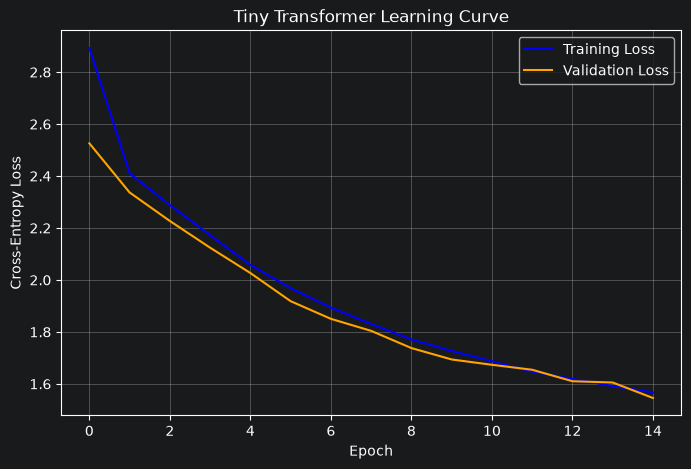

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(train_history, label="Training Loss", color="blue")
plt.plot(val_history, label="Validation Loss", color="orange")

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("Tiny Transformer Learning Curve")
plt.legend()
plt.grid(True)
plt.savefig("../results/training_loss_curve.png", dpi=300, bbox_inches="tight")
plt.show()

### Step 8: Evaluate the Model

**Question:**
> *How do we calculate validation perplexity to measure how accurately our Transformer predicts the next token[cite: 38]?*

**Explanation:**
* **Perplexity**: Defined as $exp(\text{loss})$, it represents how "surprised" the language model is by new text. Lower perplexity indicates superior predictive performance[cite: 38].

In [9]:
val_loss = evaluate("val", num_batches=20)
val_perplexity = math.exp(min(val_loss, 20))

print(f"Validation Loss: {val_loss:.4f}")
print(f"Validation Perplexity: {val_perplexity:.2f}")

Validation Loss: 1.5776
Validation Perplexity: 4.84


### Step 9: Generate Stories

**Question:**
> *How do we provide a starting prompt (such as "Once upon a time") and generate autoregressive text using our trained Tiny Transformer?*

**Explanation:**
* **Autoregressive Generation**: The model takes a prompt, predicts the probability distribution for the next character, samples from it, appends the new character to the sequence, and repeats for the desired length[cite: 38, 48].

In [10]:
block_size = 64  # Ensure block size matches model configuration

@torch.no_grad()
def generate(prompt, max_new_chars=100):
    model.eval()

    # Encode prompt string into tensor IDs
    ids = torch.tensor([encode(prompt)], dtype=torch.long, device=device)

    for _ in range(max_new_chars):
        # Crop context to the last block_size tokens
        x_cond = ids[:, -block_size:]
        logits = model(x_cond)

        # Get logits for the last token and compute probabilities
        probs = F.softmax(logits[:, -1, :], dim=-1)

        # Sample next token from the probability distribution
        next_id = torch.multinomial(probs, num_samples=1)
        ids = torch.cat([ids, next_id], dim=1)

    return decode(ids[0].tolist())

# Test story generation
prompt_text = "Once upon a time"
generated_story = generate(prompt_text, max_new_chars=150)
print("--- Generated Story Output ---")
print(generated_story)

--- Generated Story Output ---
Once upon a time. One little forr. She dina looke aind her. When unded somes ascall Lily palood aved dfante! Salloaroud. Cand theire bugirl be meas mings in into plow


### Step 10: Build an Interactive Chat Window

**Question:**
> *How do we integrate our trained character-level Transformer into a web-based chat interface using Gradio[cite: 38]?*

**Explanation:**
* **Gradio Integration**: Wraps our custom `generate` function into an interactive UI so users can query the language model directly from their browser[cite: 38].

In [11]:
import gradio as gr

def chat_with_transformer(message, history):
    if not message or not message.strip():
        return "Please enter a message."

    # Filter unsupported characters not present in vocabulary
    supported = "".join(ch for ch in message if ch in stoi)
    if not supported:
        return "Please use characters included in the training vocabulary."

    try:
        return generate(supported, max_new_chars=100)
    except Exception as e:
        return f"Generation failed: {type(e).__name__}: {e}"

demo = gr.ChatInterface(
    fn=chat_with_transformer,
    title="My Tiny Transformer Chatbot",
    description="A character-level language model trained from scratch on TinyStories."
)

# Launch the Gradio demo interface
# demo.launch(inline=False)
print("Gradio Chat interface configured successfully!")

Gradio Chat interface configured successfully!


### Step 11: Save the Trained Model

**Question:**
> *How do we serialize and save our trained Transformer model weights and vocabulary configuration for future text generation[cite: 38]?*

**Explanation:**
* **Model Checkpointing**: Saving state dictionaries along with vocabulary mappings (`stoi`, `itos`) ensures we can reload and deploy the model without retraining[cite: 38].

In [12]:
checkpoint = {
    "model_state_dict": model.state_dict(),
    "chars": chars,
    "vocab_size": vocab_size,
    "config": {
        "embedding_dim": 64,
        "num_heads": 2,
        "num_layers": 2,
        "block_size": 64,
        "feedforward_dim": 128
    }
}

torch.save(checkpoint, "../results/tiny_transformer.pt")
print("Tiny Transformer model saved successfully as '../results/tiny_transformer.pt'!")

Tiny Transformer model saved successfully as '../results/tiny_transformer.pt'!
